# DNBLab Jupyter Notebook Tutorial

## SPARQL-Abfragen auf den GND-SPARQL-Endpunkt der Deutschen Nationalbibliothek

Dieses DNBLab-Tutorial beschreibt Beispielabfragen auf den SPARQL-Endpoint der Gemeinsamen Normdatei (GND) der Deutschen Nationalbibliothek. Der Endpoint ist unter https://sparql.dnb.de/api/gnd erreichbar und ermöglicht semantische Abfragen auf die GND-Daten.
Weitere Endpunkte sind https://sparql.dnb.de/api/dnbgnd für Bibliografische Daten + GND und https://sparql.dnb.de/api/zdb für Daten der Zeitschriftendatenbank + ISIL (Adressdatei)

**Inhaltsverzeichnis:** 

* [Einrichten der Arbeitsumgebung](#API1)
* [Grundlegende SPARQL-Abfragen](#API2)
* [Fortgeschrittene Abfragen](#API3)
* [Praktische Anwendungsbeispiele](#API4)
* [Graphdaten Visualisierung](#API5)

## Einrichten der Arbeitsumgebung <a class="anchor" id="API1"></a>

Für die Abfrage des SPARQL-Endpoints benötigen wir die SPARQLWrapper-Bibliothek. Zusätzlich wird pandas für die Datenverarbeitung und die Anzeige der Ergebnisse verwendet.

In [1]:
from SPARQLWrapper import SPARQLWrapper, JSON
import pandas as pd

## Grundlegende SPARQL-Abfragen <a class="anchor" id="API2"></a>

In [2]:
# SPARQL-Endpoint konfigurieren
sparql = SPARQLWrapper("https://sparql.dnb.de/api/gnd")
sparql.setReturnFormat(JSON)

### 1. Einfache Abfrage von GND-Entitäten

In diesem Beispiel werden einfache Informationen über GND-Entitäten abgefragt. Der GND-Endpunkt verwendet das GND-Ontologie-Modell unter https://d-nb.info/standards/elementset/gnd.
Falls dieses Beispiel den Fehler "Gateway Timeout" produziert, hilft es die Abfrage ein weiteres mal auszuführen. Dann sollten die Daten im Cache liegen.

In [4]:
# Einfache SPARQL-Abfrage: Suche nach Personen mit dem Namen "Goethe" auf 10 Ergebnisse begrenzt
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?entity ?preferredName ?gndNumber WHERE {
  ?entity a gndo:DifferentiatedPerson ;
          gndo:preferredNameForThePerson ?preferredName ;
          gndo:gndIdentifier ?gndNumber .
  FILTER(CONTAINS(LCASE(?preferredName), "goethe"))
} LIMIT 10
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse anzeigen
for result in results["results"]["bindings"]:
    print(f"GND-Nummer: {result['gndNumber']['value']}")
    print(f"Name: {result['preferredName']['value']}")
    print(f"Entity: {result['entity']['value']}")
    print()

GND-Nummer: 1015367909
Name: Goethe, Friedrich
Entity: https://d-nb.info/gnd/1015367909

GND-Nummer: 1016315392
Name: Goether, Ibrahim
Entity: https://d-nb.info/gnd/1016315392

GND-Nummer: 1025546172
Name: Goethem, Pieter van
Entity: https://d-nb.info/gnd/1025546172

GND-Nummer: 1046873253
Name: Van Goethem, Geert
Entity: https://d-nb.info/gnd/1046873253

GND-Nummer: 1055161341
Name: Goethem, Fernand Antoine van
Entity: https://d-nb.info/gnd/1055161341

GND-Nummer: 1055672109
Name: Goethe, Theodor
Entity: https://d-nb.info/gnd/1055672109

GND-Nummer: 1057078735
Name: Goethe, Erika Christina
Entity: https://d-nb.info/gnd/1057078735

GND-Nummer: 105725137
Name: Goethert, Friedrich Wilhelm
Entity: https://d-nb.info/gnd/105725137

GND-Nummer: 1057568821
Name: Goethe, Walter von
Entity: https://d-nb.info/gnd/1057568821

GND-Nummer: 1061906469
Name: Goethe, Christina
Entity: https://d-nb.info/gnd/1061906469



### 2. Abfrage von GND-IDs und Bezeichnungen

Dieses Beispiel zeigt, wie man GND-IDs und ihre bevorzugten Bezeichnungen abfragt.

In [5]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?gndNumber ?preferredName ?entityType WHERE {
  ?entity a ?entityType ;
          gndo:gndIdentifier ?gndNumber ;
          gndo:preferredNameForThePerson|gndo:preferredNameForTheCorporateBody|gndo:preferredNameForTheSubjectHeading ?preferredName .
  FILTER(?entityType IN (gndo:Person, gndo:CorporateBody, gndo:SubjectHeading))
} LIMIT 20
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse als DataFrame anzeigen
data = []
for result in results["results"]["bindings"]:
    data.append({
        'GND-Nummer': result['gndNumber']['value'],
        'Name': result['preferredName']['value'],
        'Typ': result['entityType']['value'].split('#')[1]
    })

df = pd.DataFrame(data)
df

,GND-Nummer,Name,Typ
0,10000001-0,Verein der Freunde des Burghardt-Gymnasiums Bu...,CorporateBody
1,10000002-2,Evangelisch-reformierte Kirche des Kantons St....,CorporateBody
2,10000004-6,Lehr- und Erziehungsanstalt der VV Kapuziner (...,CorporateBody
3,10000005-8,Universitas Gadjah Mada. Fakultas Farmasi,CorporateBody
4,10000006-X,Allgemeine Handels-Lehranstalt von Gustav Hoff...,CorporateBody
5,10000010-1,Evangelischer Pressedienst. Landesdienst Niede...,CorporateBody
6,10000011-3,Welsh Institute of Rural Studies (Aberystwyth),CorporateBody
7,10000012-5,National Institute of Medical Herbalists,CorporateBody
8,10000014-9,Svetska Galerija na Karikaturi (Skopje),CorporateBody
9,10000015-0,Freier Deutscher Gewerkschaftsbund. Abteilung ...,CorporateBody


## Fortgeschrittene Abfragen <a class="anchor" id="API3"></a>

### 3. Abfrage mit Filtern und Sortierung

Dieses Beispiel zeigt eine komplexere Abfrage mit Filtern nach Datumsbereichen und Sortierung.

In [6]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>
PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>

SELECT ?gndNumber ?preferredName ?dateOfBirth ?dateOfDeath WHERE {
  ?entity a gndo:DifferentiatedPerson ;
          gndo:gndIdentifier ?gndNumber ;
          gndo:preferredNameForThePerson ?preferredName .
  OPTIONAL { ?entity gndo:dateOfBirth ?dateOfBirth . }
  OPTIONAL { ?entity gndo:dateOfDeath ?dateOfDeath . }
  FILTER(?dateOfBirth < "1900-01-01"^^xsd:date)
}
ORDER BY DESC(?dateOfBirth)
LIMIT 15
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse anzeigen
for result in results["results"]["bindings"]:
    print(f"GND: {result['gndNumber']['value']} - {result['preferredName']['value']}")
    if 'dateOfBirth' in result:
        print(f"  Geboren: {result['dateOfBirth']['value']}")
    if 'dateOfDeath' in result:
        print(f"  Gestorben: {result['dateOfDeath']['value']}")
    print()

GND: 1075307449 - Ganev, Mitju
  Geboren: 1900
  Gestorben: 1925

GND: 1012959279 - Maksakovskiĭ, Pavel V.
  Geboren: 1900
  Gestorben: 1928

GND: 1051182476 - Berni, Friedrich Georg
  Geboren: 1900
  Gestorben: 1946

GND: 1076543170 - Mas Collellmir, Bartomeu
  Geboren: 1900
  Gestorben: 1980

GND: 1055251987 - Mackay, B. Laurence von
  Geboren: 1900
  Gestorben: 1985

GND: 107533523X - Haegermann, Hans
  Geboren: 1900

GND: 1063825334 - Działowski, Stanisław
  Geboren: 1900
  Gestorben: 1942

GND: 1055639934 - Kamp, Joseph Peter
  Geboren: 1900

GND: 1046757954 - Kankava, Mixeil
  Geboren: 1900
  Gestorben: 1977

GND: 105777315 - Hare, Cyril
  Geboren: 1900
  Gestorben: 1958

GND: 1056702257 - Soffici, Mario
  Geboren: 1900
  Gestorben: 1977

GND: 1057384909 - Sánchez, Juan Félix
  Geboren: 1900

GND: 1024216608 - Lawson, Wilfrid
  Geboren: 1900
  Gestorben: 1966

GND: 1014335094 - Levrel, René Joseph Marie
  Geboren: 1900
  Gestorben: 1981

GND: 1046758799 - Seelhoff, Paul
  Geb

### 4. Aggregationsabfrage

Dieses Beispiel zeigt eine Abfrage mit COUNT und GROUP BY, um die Verteilung von Entitätstypen zu analysieren.

In [7]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>

SELECT ?entityType (COUNT(?entity) AS ?count) WHERE {
  ?entity a ?entityType .
  FILTER(?entityType IN (gndo:DifferentiatedPerson, gndo:CorporateBody, gndo:SubjectHeadingSensoStricto, gndo:Work, gndo:ConferenceOrEvent))
}
GROUP BY ?entityType
ORDER BY DESC(?count)
LIMIT 10
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse als DataFrame anzeigen
data = []
for result in results["results"]["bindings"]:
    data.append({
        'Entitätstyp': result['entityType']['value'].split('#')[1],
        'Anzahl': int(result['count']['value'])
    })

df = pd.DataFrame(data)
df

,Entitätstyp,Anzahl
0,DifferentiatedPerson,6637941
1,CorporateBody,1286530
2,ConferenceOrEvent,817093
3,Work,245632
4,SubjectHeadingSensoStricto,136816


## Praktische Anwendungsbeispiele <a class="anchor" id="API4"></a>

### 5. Suche nach Personen mit bestimmten Berufen

Dieses Beispiel zeigt, wie man nach Personen mit bestimmten Berufsbezeichnungen sucht.

In [8]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?gndNumber ?preferredName ?job WHERE {
  ?entity a gndo:DifferentiatedPerson ;
          gndo:gndIdentifier ?gndNumber ;
          gndo:preferredNameForThePerson ?preferredName ;
          gndo:professionOrOccupation ?profession_node .
          ?profession_node (rdf:_1|rdf:_2|rdf:_3|rdf:_4|rdf:_5|rdf:_6|rdf:_7|rdf:_8) ?jobId .
  ?jobId gndo:preferredNameForTheSubjectHeading ?job .
  FILTER (CONTAINS(LCASE(?job),"schriftsteller") || CONTAINS(LCASE(?job),"autor"))
}
LIMIT 10
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse anzeigen
for result in results["results"]["bindings"]:
    print(f"{result['preferredName']['value']} ({result['gndNumber']['value']})")
    print(f"  Beruf: {result['job']['value']}")
    print()

Ampzing, Samuel (100000649)
  Beruf: Schriftsteller

André, Rudolf (100001424)
  Beruf: Schriftsteller

Beausobre, Louis de (100002188)
  Beruf: Schriftsteller

Villemain d'Abancourt, François-Jean (100002226)
  Beruf: Schriftsteller

Achatius, von Brandenburg (100003184)
  Beruf: Autor

Alletz, Pons Augustin (100003877)
  Beruf: Schriftsteller

Aelianus, Tacticus (100005985)
  Beruf: Schriftsteller

Affarosi, Camillo (100006531)
  Beruf: Schriftsteller

Afflitto, Eustachio d' (100006574)
  Beruf: Schriftsteller

Canturani, Selvaggio (10000721X)
  Beruf: Schriftsteller



### 6. Abfrage von Werken und ihren Autoren

Dieses Beispiel zeigt, wie man Werke und ihre zugehörigen Autoren abfragt. Werke bedeutet nicht Publikationen. Um die Publikationen von Autoren abzufragen muss der SPARQL-Endpunkt https://sparql.dnb.de/api/dnbgnd verwendet werden. Dieser enthält die Publikationen der Deutschen Nationalbibliografie und die GND Entitäten.

In [9]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?work ?workTitle ?author ?authorName WHERE {
  ?work a gndo:Work ;
        gndo:preferredNameForTheWork ?workTitle ;
        gndo:creator ?author .
  ?author a gndo:DifferentiatedPerson ;
           gndo:preferredNameForThePerson ?authorName .
}
LIMIT 10
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse anzeigen
for result in results["results"]["bindings"]:
    print(f"Werk: {result['workTitle']['value']}")
    print(f"  Autor: {result['authorName']['value']}")
    print()

Werk: Druckermarke (Beck, Balthasar), 01
  Autor: Beck, Balthasar

Werk: Druckermarke (Initiale, Schott, Johann), 01
  Autor: Schott, Johann

Werk: Druckermarke (Initiale, Wappen, Schott, Johann), 01
  Autor: Schott, Johann

Werk: Druckermarke (Initiale, Schott, Johann), 02
  Autor: Schott, Johann

Werk: Druckermarke (Motto, Initiale, Schott, Johann), 01
  Autor: Schott, Johann

Werk: Le curial
  Autor: Chartier, Alain

Werk: Druckermarke (Motto, Bertram, Anton), 01
  Autor: Bertram, Anton

Werk: Druckermarke (Bertram, Anton), 01
  Autor: Bertram, Anton

Werk: Druckermarke (Initiale, Christoph von der Heyden Erben; Dietzel, Kaspar), 01
  Autor: Dietzel, Kaspar

Werk: Druckermarke (Initiale, Heyden, Christoph von der), 03
  Autor: Heyden, Christoph von der



### 7. Geografische Abfrage nach Orten

Dieses Beispiel zeigt, wie man nach Entitäten mit geografischen Bezügen sucht.

In [10]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>

SELECT ?entity ?preferredName ?place ?placeName WHERE {
  ?entity a gndo:DifferentiatedPerson ;
          gndo:preferredNameForThePerson ?preferredName ;
          gndo:placeOfActivity ?place .
  ?place a gndo:PlaceOrGeographicName ;
         gndo:preferredNameForThePlaceOrGeographicName ?placeName .
  FILTER(CONTAINS(LCASE(?placeName), "berlin"))
}
LIMIT 10
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse anzeigen
for result in results["results"]["bindings"]:
    print(f"{result['preferredName']['value']} - {result['placeName']['value']}")
    print()

Winkler, Fritz - Bernau bei Berlin (Region)

Lutz, Fabian - Handwerkskammerbezirk Berlin

Rosenfeld, Philipp - Berlin (Region)

Rohner, Dagobert - Berlin (Region)

Paul, Mechthild - Berlin-Brandenburg (Planungsregion)

Leomar, Andy - Berlin (Region)

Schulze, Franz - Berlin (Region)

Benedikt, Reg - Berlin (Region)

Steenken, Stefanie - Berlin (Region)

Fleck, Anna - Berlin (Region, Nord)



### 8. Graphdaten Visualisierung

Dieses Beispiel zeigt, wie die Beziehung von Personen zu Organisationen abgefragt und über eine Graphvisualisierungen Überschneidungen mit anderen Personen visualisiert werden kann.

#### 8.1 SPARQL-Abfrage von Personenbeziehungen

Dieser Codeblock holt die Daten und bereitet sie für die Visualisierung vor, die im nächsten Schritt erstellt wird.

In [14]:
query = """
PREFIX gndo: <https://d-nb.info/standards/elementset/gnd#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
SELECT ?preferredName ?affiliationName WHERE {
  ?entity a gndo:DifferentiatedPerson ;
    gndo:preferredNameForThePerson ?preferredName ;
    gndo:affiliation ?affiliation ;
    gndo:placeOfActivity <https://d-nb.info/gnd/4035206-7> ; # Leipzig
	gndo:professionOrOccupation ?profession_node .
    ?profession_node (rdf:_1|rdf:_2|rdf:_3|rdf:_4|rdf:_5|rdf:_6|rdf:_7|rdf:_8) <https://d-nb.info/gnd/4040841-3> . # Musiker
  ?affiliation a gndo:CorporateBody ;
    gndo:preferredNameForTheCorporateBody ?affiliationName .
}
LIMIT 100
"""

sparql.setQuery(query)
results = sparql.query().convert()

# Ergebnisse als DataFrame speichern
df = pd.DataFrame(results["results"]["bindings"])
df['preferredName'] = df['preferredName'].apply(lambda x: x['value'])
df['affiliationName'] = df['affiliationName'].apply(lambda x: x['value'])


#### 8.2 Netzwerkerkvisualisierung mit NetworkX

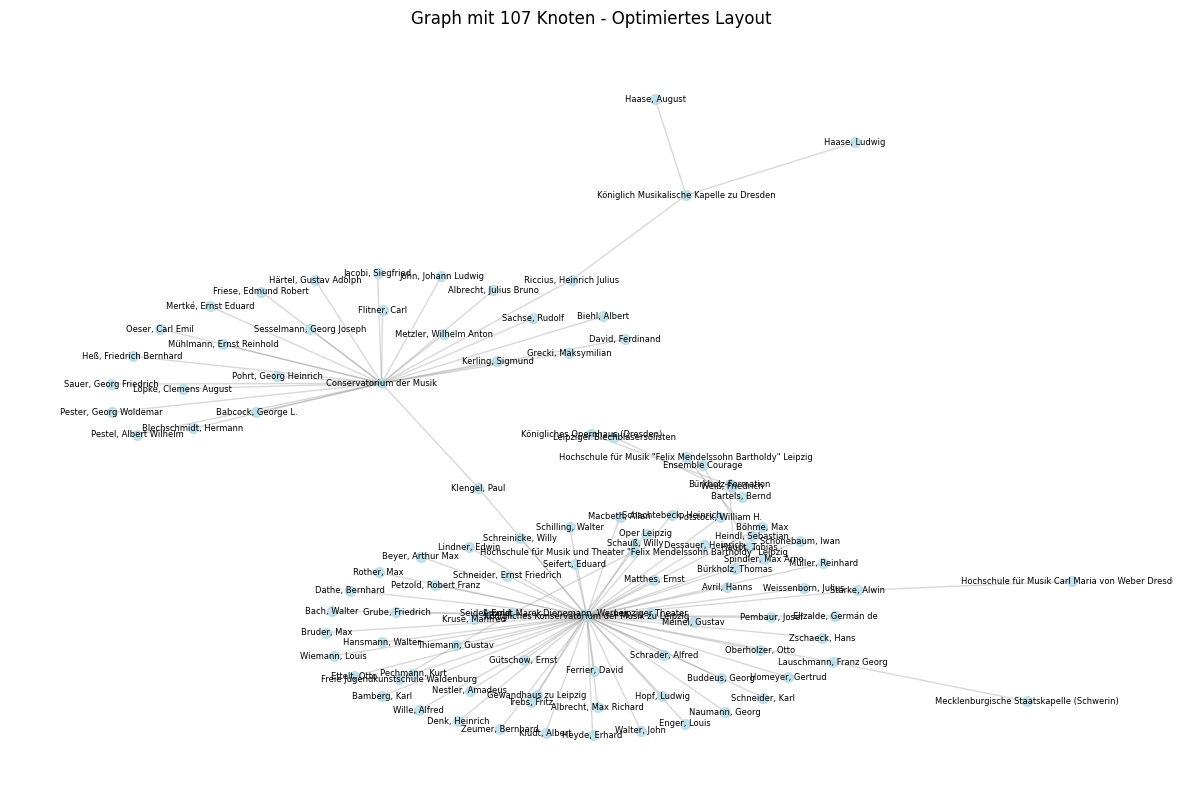

In [12]:
import networkx as nx
import matplotlib.pyplot as plt

# Für Graphdaten (z.B. Beziehungen zwischen Entitäten)
G = nx.Graph()

# Füge Knoten und Kanten hinzu
for row in results["results"]["bindings"]:
    person = row['preferredName']['value']
    affiliation  = row['affiliationName']['value']  # Beispiel für Beziehung
    G.add_edge(person, affiliation)

def smart_layout(G, figsize=(15, 10)):
    num_nodes = len(G.nodes())
    
    plt.figure(figsize=figsize)
    
    if num_nodes < 20:
        # Kleiner Graph - Spring Layout mit wenig Abstand
        pos = nx.spring_layout(G, k=1, iterations=50, seed=42)
        node_size = 200
        font_size = 10
        
    elif num_nodes < 100:
        # Mittlerer Graph - Spring Layout mit mehr Abstand
        pos = nx.spring_layout(G, k=2, iterations=100, seed=42)
        node_size = 100
        font_size = 8
        
    else:
        # Großer Graph - Kamada-Kawai Layout
        pos = nx.kamada_kawai_layout(G)
        node_size = 50
        font_size = 6
    
    # Zeichne den Graphen
    nx.draw_networkx_nodes(G, pos, node_size=node_size, 
                          node_color='lightblue', alpha=0.7)
    
    nx.draw_networkx_edges(G, pos, alpha=0.3, edge_color='gray')

    nx.draw_networkx_labels(G, pos, font_size=font_size)
    
    plt.axis('off')
    plt.title(f'Graph mit {num_nodes} Knoten - Optimiertes Layout')
    return pos

pos = smart_layout(G)
plt.show()